<a href="https://colab.research.google.com/github/tutorbosun/navier-stokes-python-solver/blob/main/01_1D_Linear_Convection_CFL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

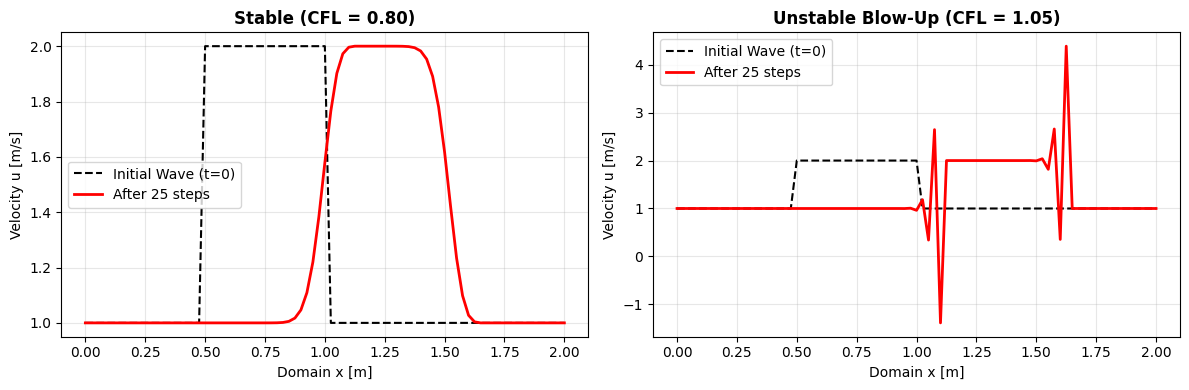

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def solve_1d_convection(nx, cfl, nt=25, c=1.0):
    L = 2.0
    dx = L / (nx - 1)
    dt = cfl * dx / c  # Time step governed by Courant (CFL) number
    x = np.linspace(0, L, nx)

    # Initial condition: Square wave (u = 2 between x=0.5 and x=1.0, else 1)
    u = np.ones(nx)
    u[int(0.5 / dx):int(1.0 / dx + 1)] = 2.0
    u_init = u.copy()

    # Upwind finite-difference time marching
    for n in range(nt):
        un = u.copy()
        for i in range(1, nx):
            u[i] = un[i] - c * (dt / dx) * (un[i] - un[i - 1])

    return x, u_init, u

# Compare stable CFL = 0.8 vs unstable CFL = 1.05
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, cfl, title in zip(axes, [0.8, 1.05], ["Stable (CFL = 0.80)", "Unstable Blow-Up (CFL = 1.05)"]):
    x, u0, u_final = solve_1d_convection(nx=81, cfl=cfl)
    ax.plot(x, u0, 'k--', label='Initial Wave (t=0)')
    ax.plot(x, u_final, 'r-', linewidth=2, label=f'After 25 steps')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Domain x [m]')
    ax.set_ylabel('Velocity u [m/s]')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('cfl_stability_comparison.png', dpi=300)
plt.show()
